# Preprocesamiento_Limpieza

Objetivo: Transformación tabular y consolidación del panel

Contenido:

- Unión (Merge) de las bases usando pandas.
- Filtro de exclusión por discontinuidad: eliminar a Venezuela, Cuba, Timor-Leste, Emiratos Árabes, etc., para garantizar los 56 países.
- Estructuración del panel temporal balanceado (2004-2024, 61.600 observaciones diádicas).
- Imputación de valores faltantes (la imputación por mediana que mencionas en la metodología para PIB y distancia).

Salida (Output): El archivo maestro consolidado, por ejemplo, base_comercio_ERGM_clean.csv

## Librerias

In [141]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import random
import math
import os

pd.set_option('display.max_columns', None)
pd.options.display.float_format = '{:.2f}'.format

In [142]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Importacion de datos

### Redes de convenios
Obtenidos de https://www.treaties.tax/en/

ICTD (2021). Tax Treaties Explorer [Online database], Brighton: International Centre for Tax and Development (ICTD), retrieved from https://www.treaties.tax

In [4]:
base_convenios=pd.read_csv('https://github.com/hubcborja/Trabajo_grado_ECIJG/raw/refs/heads/main/bases_datos/base_convenios_seleccion.csv')
# diccionario nombre de las columnas con artículo a nombre del artículo

base_convenios.head()

,pais_origen,pais_destino,Anio_firma,Anio_vigencia,Status,Type
0,Albania,Austria,2007,2009.00,Superseded,Original
1,Albania,Austria,2019,2021.00,In Force,Amended by MLI
2,Albania,Belgium,2002,2005.00,Superseded,Original
3,Albania,Belgium,2019,2021.00,In Force,Amended by MLI
4,Albania,Bosnia and Herzegovina,2008,2013.00,Superseded,Original


In [47]:
print(base_convenios.loc[(base_convenios['pais_origen']=='Colombia')])

     pais_origen          pais_destino  Anio_firma  Anio_vigencia  \
1272    Colombia                 Japan        2018        2023.00   
1273    Colombia        Czech Republic        2012        2016.00   
1274    Colombia        Czech Republic        2017            NaN   
1275    Colombia                 Spain        2005        2008.00   
1276    Colombia                 Spain        2017            NaN   
1277    Colombia  United Arab Emirates        2017            NaN   
1278    Colombia            Luxembourg        2022            NaN   
1279    Colombia                 Italy        2018        2022.00   
1280    Colombia               Uruguay        2021            NaN   
1281    Colombia           Netherlands        2022            NaN   
1282    Colombia           Switzerland        2007        2012.00   
1283    Colombia                Mexico        2009        2013.00   
1284    Colombia           South Korea        2010        2015.00   
1285    Colombia              Port

In [49]:
print(base_convenios.loc[(base_convenios['pais_origen']=='Canada')&(base_convenios['pais_destino']=='China')])

    pais_origen pais_destino  Anio_firma  Anio_vigencia      Status  \
964      Canada        China        1986        1987.00  Superseded   
965      Canada        China        2017        2023.00    In Force   

               Type  
964        Original  
965  Amended by MLI  


### Comtrade

United Nations Statistics Division. (2026). UN Comtrade Database [Data set]. United Nations. https://comtradeplus.un.org/

In [12]:
comtrade=pd.read_csv('https://github.com/hubcborja/Trabajo_grado_ECIJG/raw/refs/heads/main/bases_datos/Comtrade_canasta_socios_significativos_2004_2024.csv')

print(comtrade.shape)
comtrade=comtrade.loc[comtrade['reporter_iso_limpio']!=comtrade['partner_iso_limpio']]
comtrade=comtrade.loc[comtrade['reporter_iso_limpio']!='S19']
comtrade=comtrade.loc[comtrade['partner_iso_limpio']!='S19']
print(comtrade.shape)
comtrade.head()

(221723, 8)
(220428, 8)


,refYear,reporter_iso_limpio,partner_iso_limpio,M,X,peso_comercio_total,balanza_comercial,ln_peso_comercio_total
0,2004,ARE,AFG,82.00,129551474.00,129551556.00,129551392.00,18.68
1,2004,ARE,AGO,0.00,23262625.00,23262625.00,23262625.00,16.96
2,2004,ARE,ALB,0.00,144527.00,144527.00,144527.00,11.88
3,2004,ARE,AND,0.00,24592.00,24592.00,24592.00,10.11
4,2004,ARE,ANT,0.00,126744.00,126744.00,126744.00,11.75


In [105]:
comtrade[comtrade.duplicated(keep=False)]

,year,iso3_o,iso3_d,M,X,peso_comercio_total,balanza_comercial,ln_peso_comercio_total,iso3_par


### Gravity

Desde la biblioteca del Gravity

Conte, M., P. Cotterlaz and T. Mayer (2022), "The CEPII Gravity database". CEPII Working Paper N°2022-05, July 2022.

In [14]:
gravity=pd.read_csv('https://github.com/hubcborja/Trabajo_grado_ECIJG/raw/refs/heads/main/bases_datos/gravity_seleccion.csv')
print(gravity.shape)
gravity=gravity[gravity['year']>=2004]
print(gravity.shape)
print(gravity.columns)
gravity[gravity['iso3_o']=='COL'].head()

(1143072, 14)
(1143072, 14)
Index(['year', 'country_id_o', 'country_id_d', 'iso3_o', 'iso3_d', 'dist',
       'fta_wto', 'entry_cost_o', 'entry_cost_d', 'entry_proc_o',
       'entry_proc_d', 'entry_time_o', 'entry_time_d', 'comlang_off'],
      dtype='object')


,year,country_id_o,country_id_d,iso3_o,iso3_d,dist,fta_wto,entry_cost_o,entry_cost_d,entry_proc_o,entry_proc_d,entry_time_o,entry_time_d,comlang_off
208656,2004,COL,ABW,COL,ABW,982.00,0.00,25.60,NaN,11.00,NaN,40.00,NaN,1.00
208657,2005,COL,ABW,COL,ABW,982.00,0.00,24.70,NaN,11.00,NaN,40.00,NaN,1.00
208658,2006,COL,ABW,COL,ABW,982.00,0.00,19.10,NaN,12.00,NaN,41.00,NaN,1.00
208659,2007,COL,ABW,COL,ABW,982.00,0.00,18.60,NaN,11.00,NaN,40.00,NaN,1.00
208660,2008,COL,ABW,COL,ABW,982.00,0.00,14.90,NaN,9.00,NaN,34.00,NaN,1.00


In [15]:
# Base de indices de los paises obtenida desde la biblioteca del Gravity
countries=pd.read_csv('/content/drive/MyDrive/Gravity/Countries_V202211.csv')
print(countries.columns)
countries=countries[['iso3', 'country']]
otros=pd.DataFrame({'iso3':['GGY','IMN','JEY','XKK'],'country':['Guernsey','Isle of Man','Jersey','Kosovo']})
countries=pd.concat([countries, otros], ignore_index=True)
countries.head()

Index(['country_id', 'iso3', 'iso3num', 'country', 'countrylong', 'first_year',
       'last_year', 'countrygroup_iso3', 'countrygroup_iso3num', 'iso2',
       'heg_iso3_2020', 'heg_iso3num_2020'],
      dtype='object')


,iso3,country
0,AFG,Afghanistan
1,ALB,Albania
2,DZA,Algeria
3,ASM,American Samoa
4,AND,Andorra


In [104]:
gravity[gravity.duplicated(keep=False)]

,year,country_id_o,country_id_d,iso3_o,iso3_d,dist,fta_wto,entry_cost_o,entry_cost_d,entry_proc_o,entry_proc_d,entry_time_o,entry_time_d,comlang_off,iso3_par


### Datos del banco mundial

In [18]:
bancomundial=pd.read_csv('https://raw.githubusercontent.com/hubcborja/Trabajo_grado_ECIJG/refs/heads/main/bases_datos/bancomundial_seleccion.csv')
print(bancomundial.shape)
bancomundial.head()

(4774, 8)


,year,pais,iso3,FDI_ingreso_neto_porc_PIB,FDI_egreso_neto_porc_PIB,pib_per_capita_dolares_constantes,pib_ppp_dolares_constantes,pib_dolares_constantes
0,2004,Afghanistan,AFG,3.58,-0.01,338.64,41865355064.30,7978515641.58
1,2004,Albania,ALB,4.61,0.18,2567.30,25678413443.54,7771053341.65
2,2004,Algeria,DZA,0.96,0.27,4066.28,431566672844.75,132675813620.93
3,2004,American Samoa,ASM,NaN,NaN,13291.54,NaN,755198473.28
4,2004,Andorra,AND,NaN,NaN,40054.34,4783072832.93,2977038818.12


In [103]:
bancomundial[bancomundial.duplicated(keep=False)]

,year,pais,iso3,FDI_ingreso_neto_porc_PIB,FDI_egreso_neto_porc_PIB,pib_per_capita_dolares_constantes,pib_ppp_dolares_constantes,pib_dolares_constantes


# Limpieza y tratamiento de los datos

## Limpieza en base de convenios para evitar doble tributacion

In [26]:
# Convenios con nombre de los paises para luego unirla con gravity
nom_paises_nomatch={'DR Congo':'Congo, Democratic Rep. of the',
'Republic of the Congo':'Congo, Rep. of the',
'Curaçao':'Curacao',
'Czechia':'Czech Republic',
'Ivory Coast':'Cote d\'Ivoire',
'Macau':'Macao',
'United States':'United States of America',
'São Tomé and Príncipe':'Sao Tome and Principe'}
base_convenios['pais_origen'] = base_convenios['pais_origen'].replace(nom_paises_nomatch)
base_convenios['pais_destino'] = base_convenios['pais_destino'].replace(nom_paises_nomatch)
base_convenios_nombres=base_convenios.merge(countries, left_on='pais_origen', right_on='country', how='left')
base_convenios_nombres=base_convenios_nombres.merge(countries, left_on='pais_destino', right_on='country', how='left')
base_convenios_nombres.drop(columns=['country_x', 'country_y'], inplace=True)
base_convenios_nombres=base_convenios_nombres.rename(columns={'iso3_x':'iso3_origen', 'iso3_y':'iso3_destino'})
convenios_colombia_faltantes=pd.DataFrame({'iso3_origen':['COL', 'COL', 'COL', 'COL'],
                                           'iso3_destino':['BRA', 'PER', 'ECU', 'BOL'],
                                           'pais_origen':['Colombia', 'Colombia', 'Colombia', 'Colombia'],
                                           'pais_destino':['Brazil', 'Peru', 'Ecuador', 'Bolivia'],
                                           'Anio_firma':[2022, 2004, 2004, 2004],
                                           'Anio_vigencia':[np.nan, 2005, 2005, 2005 ],
                                           'Status':['Not In Force', 'In Force', 'In Force', 'In Force'],
                                           'Type':['Original', 'Multilateral',  'Multilateral', 'Multilateral']})
base_convenios_nombres=pd.concat([base_convenios_nombres,convenios_colombia_faltantes])
base_convenios_nombres['iso3_par']=base_convenios_nombres.apply(lambda row: tuple(sorted((row['iso3_origen'], row['iso3_destino']))), axis=1)
base_convenios_nombres.head()


,pais_origen,pais_destino,Anio_firma,Anio_vigencia,Status,Type,iso3_origen,iso3_destino,iso3_par
0,Albania,Austria,2007,2009.00,Superseded,Original,ALB,AUT,"(ALB, AUT)"
1,Albania,Austria,2019,2021.00,In Force,Amended by MLI,ALB,AUT,"(ALB, AUT)"
2,Albania,Belgium,2002,2005.00,Superseded,Original,ALB,BEL,"(ALB, BEL)"
3,Albania,Belgium,2019,2021.00,In Force,Amended by MLI,ALB,BEL,"(ALB, BEL)"
4,Albania,Bosnia and Herzegovina,2008,2013.00,Superseded,Original,ALB,BIH,"(ALB, BIH)"


In [27]:
base_convenios_nombres.loc[(base_convenios_nombres['iso3_origen']=='COL')&(base_convenios_nombres['iso3_destino']=='ITA')].head()

,pais_origen,pais_destino,Anio_firma,Anio_vigencia,Status,Type,iso3_origen,iso3_destino,iso3_par
1279,Colombia,Italy,2018,2022.00,In Force,Original,COL,ITA,"(COL, ITA)"


### Estadisticas para los 56 países de interés

In [28]:
sin_iso = base_convenios_nombres[base_convenios_nombres[['iso3_origen', 'iso3_destino']].isna().any(axis=1)]
print("Convenios sin ISO3:\n", sin_iso[['pais_origen', 'pais_destino']].drop_duplicates())

print(base_convenios_nombres['Type'].value_counts())
print(base_convenios_nombres['Status'].value_counts())

Convenios sin ISO3:
 Empty DataFrame
Columns: [pais_origen, pais_destino]
Index: []
Type
Original               2311
Amended by MLI          912
Amended by protocol     327
Pre-independence        317
Multilateral             11
Name: count, dtype: int64
Status
In Force        1994
Superseded       812
Not In Force     719
Terminated       353
Name: count, dtype: int64


In [56]:
# Estadisticas para los 56 países de interés
iso_56 = ['ARG','AUS','AUT','BEL','BOL','BRA','CAN','CHE','CHL','CHN','COL','CRI','CZE',
          'DEU','DNK','ECU','ESP','EST','FIN','FRA','GBR','GRC','GUY','HUN','IDN','IND',
          'IRL','ISL','ISR','ITA','JPN','KHM','KOR','LTU','LUX','LVA','MEX','MYS','NLD',
          'NOR','NZL','PAN','PER','PHL','POL','PRT','PRY','SGP','SUR','SVK','SVN','SWE',
          'THA','TUR','URY','USA']

# Restringir a díadas entre los 56
sub = base_convenios_nombres[
    base_convenios_nombres['iso3_origen'].isin(iso_56) &
    base_convenios_nombres['iso3_destino'].isin(iso_56)
].copy()
print("Registros brutos entre los 56 países:", len(sub))

# Filtro clave: excluir enmiendas MLI
originales = sub[sub['Type'] != 'Amended by MLI']

# --- ESTADÍSTICAS DE FIRMA ---
primer_anio_firma = originales.groupby('iso3_par')['Anio_firma'].min().dropna()
print("\n--- ESTADÍSTICAS DE FIRMA (Acuerdos Originales) ---")
print("Convenios bilaterales únicos firmados:", len(primer_anio_firma))
print("Firmados antes de 2004 (Stock inicial):", (primer_anio_firma < 2004).sum())
print("Firmados durante el panel (2004-2024):", ((primer_anio_firma >= 2004) & (primer_anio_firma <= 2024)).sum())
print("\nDistribución de firmas anuales (2004-2024):")
print(primer_anio_firma[(primer_anio_firma >= 2004) & (primer_anio_firma <= 2024)].value_counts().sort_index())

# --- ESTADÍSTICAS DE VIGENCIA (IN FORCE) ---
primer_anio_vigencia = originales.groupby('iso3_par')['Anio_vigencia'].min().dropna()
print("\n--- ESTADÍSTICAS DE ENTRADA EN VIGOR (In Force) ---")
print("Convenios bilaterales únicos que han entrado en vigor:", len(primer_anio_vigencia))
print("En vigor antes de 2004 (Stock inicial activo):", (primer_anio_vigencia < 2004).sum())
print("Entraron en vigor durante el panel (2004-2024):", ((primer_anio_vigencia >= 2004) & (primer_anio_vigencia <= 2024)).sum())
print("\nDistribución de entradas en vigor anuales (2004-2024):")
print(primer_anio_vigencia[(primer_anio_vigencia >= 2004) & (primer_anio_vigencia <= 2024)].value_counts().sort_index())

Registros brutos entre los 56 países: 699

--- ESTADÍSTICAS DE FIRMA (Acuerdos Originales) ---
Convenios bilaterales únicos firmados: 332
Firmados antes de 2004 (Stock inicial): 251
Firmados durante el panel (2004-2024): 81

Distribución de firmas anuales (2004-2024):
Anio_firma
2004    5
2005    3
2006    5
2007    4
2008    3
2009    3
2010    4
2011    7
2012    9
2013    5
2014    1
2015    4
2016    4
2017    3
2018    6
2019    7
2020    1
2021    1
2022    6
Name: count, dtype: int64

--- ESTADÍSTICAS DE ENTRADA EN VIGOR (In Force) ---
Convenios bilaterales únicos que han entrado en vigor: 315
En vigor antes de 2004 (Stock inicial activo): 231
Entraron en vigor durante el panel (2004-2024): 84

Distribución de entradas en vigor anuales (2004-2024):
Anio_vigencia
2004.00    7
2005.00    6
2006.00    6
2007.00    3
2008.00    4
2009.00    2
2010.00    3
2011.00    4
2012.00    4
2013.00    5
2014.00    8
2015.00    6
2016.00    5
2017.00    2
2018.00    3
2019.00    3
2020.00    3

In [54]:
print(base_convenios_nombres[base_convenios_nombres['Type'] == 'Multilateral'])

               pais_origen  pais_destino  Anio_firma  Anio_vigencia  \
725                  Benin  Burkina Faso        1971        1971.00   
927           Burkina Faso         Benin        2008        2010.00   
936                Burundi         Kenya        2010            NaN   
2018                Guyana      Barbados        1995        1996.00   
2505         Cote d'Ivoire  Burkina Faso        1984        1985.00   
2631                 Kenya      Tanzania        1997            NaN   
2778                 Libya       Algeria        1990        1994.00   
3850  United Arab Emirates     Palestine        1973        1975.00   
1                 Colombia          Peru        2004        2005.00   
2                 Colombia       Ecuador        2004        2005.00   
3                 Colombia       Bolivia        2004        2005.00   

            Status          Type iso3_origen iso3_destino    iso3_par  
725     Terminated  Multilateral         BEN          BFA  (BEN, BFA)  
927

In [55]:
conv_todas = base_convenios_nombres.copy()   # todas las versiones, incluido MLI (para el estado del par)

# Estado actual del par
con_efecto = conv_todas.dropna(subset=['Anio_vigencia'])
ultima = (con_efecto.sort_values(['Anio_vigencia', 'Anio_firma'])
                    .groupby('iso3_par').tail(1))
terminados = ultima.loc[ultima['Status'] == 'Terminated', 'iso3_par']

# Año de inicio primera versión con efecto, SIN contar el ML
sin_mli = conv_todas[conv_todas['Type'] != 'Amended by MLI']
inicio = (sin_mli.dropna(subset=['Anio_vigencia'])
                 .groupby('iso3_par')['Anio_vigencia'].min())

# Alertas para revisión manual
iso_56_set = set(iso_56)
en_56 = lambda s: s.apply(lambda p: p[0] in iso_56_set and p[1] in iso_56_set)

# a) Pares que solo aparecen por el MLI: el MLI solo cubre convenios existentes,
#    así que el original falta en la base y hay que buscar su año de vigencia
tipos = conv_todas.groupby('iso3_par')['Type'].agg(set)
solo_mli = tipos[tipos.apply(lambda s: s <= {'Amended by MLI'})].index.to_series()
print("Solo MLI (falta el original):\n", solo_mli[en_56(solo_mli)].tolist())

# b) Terminados: la base no trae fecha de terminación, se completa a mano
print("Terminados:\n", ultima[ultima['iso3_par'].isin(terminados) & en_56(ultima['iso3_par'])]
      [['iso3_par', 'Type', 'Anio_vigencia']])

# c) Versiones 'In Force' sin año de efecto (no deberían existir)
print("In Force sin año:\n", conv_todas[(conv_todas['Status'] == 'In Force') &
                                         conv_todas['Anio_vigencia'].isna()][['iso3_par', 'Type']])


Solo MLI (falta el original):
 []
Terminados:
         iso3_par      Type  Anio_vigencia
3398  (PER, SWE)  Original        1969.00
849   (BRA, DEU)  Original        1976.00
135   (ARG, AUT)  Original        1978.00
In Force sin año:
         iso3_par            Type
93    (DZA, LBY)        Original
94    (DZA, MAR)        Original
2266  (IDN, SDN)        Original
2325  (IDN, MNG)  Amended by MLI


In [58]:
# Excluir las modificaciones del MLI para buscar el origen del tratado
convenios_sin_mli = base_convenios_nombres[~base_convenios_nombres['Type'].isin(['Amended by MLI', 'Amended by protocol'])].copy()

# Obtener el año mínimo de firma y de vigencia por cada par de países
anio_formacion_tratado = convenios_sin_mli.groupby('iso3_par', as_index=False).agg(
    min_Anio_firma=('Anio_firma', 'min'),
    min_Anio_vigencia=('Anio_vigencia', 'min')
)

# Eliminar los que tienen NaN en vigencia
anio_formacion_tratado = anio_formacion_tratado.dropna(subset=['min_Anio_vigencia'])

print("Díadas con CDT en vigor:", anio_formacion_tratado.shape[0])
anio_formacion_tratado.head()

Díadas con CDT en vigor: 2061


,iso3_par,min_Anio_firma,min_Anio_vigencia
0,"(AGO, ARE)",2018,2018.00
1,"(AGO, CHN)",2018,2023.00
4,"(AGO, PRT)",2018,2020.00
6,"(ALB, ARE)",2014,2014.00
7,"(ALB, AUT)",2007,2009.00


In [102]:
anio_formacion_tratado[anio_formacion_tratado.duplicated(keep=False)]

,iso3_par,min_Anio_firma,min_Anio_vigencia


## Union bases de datos



### Union Comtrade - Convenios

In [112]:
# Crear la llave diádica en Comtrade para cruzar con convenios
comtrade['iso3_par'] = comtrade.apply(lambda row: tuple(sorted((row['iso3_o'], row['iso3_d']))), axis=1)
conv_comtrade = comtrade.merge(anio_formacion_tratado, on='iso3_par', how='left')

# Calcular CDT_vigente: 1 si el año del panel es >= al año de entrada en vigor
conv_comtrade['CDT_vigente'] = np.where(conv_comtrade['year'] >= conv_comtrade['min_Anio_vigencia'], 1, 0)
conv_comtrade['CDT_vigente'] = conv_comtrade['CDT_vigente'].fillna(0)
print(conv_comtrade.shape)
conv_comtrade[conv_comtrade.duplicated(keep=False)]

(220428, 12)


,year,iso3_o,iso3_d,M,X,peso_comercio_total,balanza_comercial,ln_peso_comercio_total,iso3_par,min_Anio_firma,min_Anio_vigencia,CDT_vigente


### Unión con Banco Mundial

In [111]:
# Para el país de origen (o)
conv_comtrade_bm = conv_comtrade.merge(bancomundial.drop(columns=['pais']),
                                  how='left', left_on=['year', 'iso3_o'], right_on=['year', 'iso3'])
conv_comtrade_bm.drop(columns=['iso3'], inplace=True)

# Para el país de destino (d)
conv_comtrade_bm = conv_comtrade_bm.merge(bancomundial.drop(columns=['pais']),
                                  how='left', left_on=['year', 'iso3_d'], right_on=['year', 'iso3'], suffixes=('_o', '_d'))
conv_comtrade_bm.drop(columns=['iso3'], inplace=True)

# Corregir tipos numéricos
conv_comtrade_bm['pib_per_capita_dolares_constantes_o'] = pd.to_numeric(conv_comtrade_bm['pib_per_capita_dolares_constantes_o'], errors='coerce')
conv_comtrade_bm['pib_per_capita_dolares_constantes_d'] = pd.to_numeric(conv_comtrade_bm['pib_per_capita_dolares_constantes_d'], errors='coerce')

# Cálculo de la masa económica (Origen + Destino)
conv_comtrade_bm['ln_gdp_prod'] = (np.log(conv_comtrade_bm['pib_per_capita_dolares_constantes_o'].clip(lower=1)) +
                               np.log(conv_comtrade_bm['pib_per_capita_dolares_constantes_d'].clip(lower=1)))
print(conv_comtrade_bm.shape)
conv_comtrade_bm[conv_comtrade_bm.duplicated(keep=False)]

(220428, 23)


,year,iso3_o,iso3_d,M,X,peso_comercio_total,balanza_comercial,ln_peso_comercio_total,iso3_par,min_Anio_firma,min_Anio_vigencia,CDT_vigente,FDI_ingreso_neto_porc_PIB_o,FDI_egreso_neto_porc_PIB_o,pib_per_capita_dolares_constantes_o,pib_ppp_dolares_constantes_o,pib_dolares_constantes_o,FDI_ingreso_neto_porc_PIB_d,FDI_egreso_neto_porc_PIB_d,pib_per_capita_dolares_constantes_d,pib_ppp_dolares_constantes_d,pib_dolares_constantes_d,ln_gdp_prod


### Unión con Gravity e imputacion de valores

In [113]:
# Seleccionar solo las columnas necesarias de Gravity para no duplicar llaves
cols_gravity = ['year', 'iso3_o', 'iso3_d', 'dist', 'fta_wto', 'comlang_off',
                'entry_cost_o', 'entry_cost_d', 'entry_proc_o', 'entry_proc_d',
                'entry_time_o', 'entry_time_d']
gravity_subset = gravity[cols_gravity]
gravity_subset = gravity[cols_gravity].drop_duplicates(subset=['year', 'iso3_o', 'iso3_d'])

conv_comtrade_bm_grav = conv_comtrade_bm.merge(gravity_subset, on=['year', 'iso3_o', 'iso3_d'], how='left')

# Ordenar estrictamente para que el ffill temporal respete la línea de tiempo por díada
conv_comtrade_bm_grav = conv_comtrade_bm_grav.sort_values(by=['iso3_o', 'iso3_d', 'year'])

# Rellenar los años 2022-2024 con los últimos datos disponibles (2021) de Gravity
vars_a_rellenar = ['dist', 'fta_wto', 'comlang_off', 'entry_cost_o', 'entry_cost_d',
                   'entry_proc_o', 'entry_proc_d', 'entry_time_o', 'entry_time_d']

conv_comtrade_bm_grav[vars_a_rellenar] = conv_comtrade_bm_grav.groupby(['iso3_o', 'iso3_d'])[vars_a_rellenar].ffill()

print(conv_comtrade_bm_grav.shape)
conv_comtrade_bm_grav.loc[(conv_comtrade_bm_grav['iso3_o'] == 'COL') & (conv_comtrade_bm_grav['iso3_d'] == 'FRA')]


(220428, 32)


,year,iso3_o,iso3_d,M,X,peso_comercio_total,balanza_comercial,ln_peso_comercio_total,iso3_par,min_Anio_firma,min_Anio_vigencia,CDT_vigente,FDI_ingreso_neto_porc_PIB_o,FDI_egreso_neto_porc_PIB_o,pib_per_capita_dolares_constantes_o,pib_ppp_dolares_constantes_o,pib_dolares_constantes_o,FDI_ingreso_neto_porc_PIB_d,FDI_egreso_neto_porc_PIB_d,pib_per_capita_dolares_constantes_d,pib_ppp_dolares_constantes_d,pib_dolares_constantes_d,ln_gdp_prod,dist,fta_wto,comlang_off,entry_cost_o,entry_cost_d,entry_proc_o,entry_proc_d,entry_time_o,entry_time_d
2054,2004,COL,FRA,99273779.00,149931582.00,249205361.00,50657803.00,19.33,"(COL, FRA)",2015.00,2023.00,0,2.66,0.16,4311.92,482230573793.39,179130660092.78,1.69,2.90,34557.15,2992433774420.27,2166995343501.89,18.82,8632.00,0.00,0.00,25.60,1.10,11.00,5.00,40.00,7.00
11740,2005,COL,FRA,140034701.00,122636637.00,262671338.00,-17398064.00,19.39,"(COL, FRA)",2015.00,2023.00,0,7.03,3.29,4457.28,505516336190.34,187780451739.38,3.88,5.42,34946.04,3048947856501.29,2207920477337.34,18.86,8632.00,0.00,0.00,24.70,1.20,11.00,5.00,40.00,7.00
21515,2006,COL,FRA,139717670.00,295387340.00,435105010.00,155669670.00,19.89,"(COL, FRA)",2015.00,2023.00,0,4.17,0.78,4694.03,539471204741.43,200393418124.05,3.41,5.63,35645.42,3131698267518.58,2267844862926.15,18.94,8632.00,0.00,0.00,19.10,1.10,12.00,5.00,41.00,7.00
31401,2007,COL,FRA,207836038.00,337811777.00,545647815.00,129975739.00,20.12,"(COL, FRA)",2015.00,2023.00,0,4.31,0.62,4947.25,575821824818.31,213896316785.02,3.15,4.98,36322.17,3210945324824.36,2325232266328.63,19.01,8632.00,0.00,0.00,18.60,1.10,11.00,5.00,40.00,7.00
41344,2008,COL,FRA,584327694.00,205444832.00,789772526.00,-378882862.00,20.49,"(COL, FRA)",2015.00,2023.00,0,4.36,1.27,5048.57,594728624564.41,220919487240.85,2.32,4.65,36257.37,3223152421770.07,2334072135222.36,19.03,8632.00,0.00,0.00,14.90,1.00,9.00,5.00,34.00,6.50
51428,2009,COL,FRA,1218923102.00,174937843.00,1393860945.00,-1043985259.00,21.06,"(COL, FRA)",2015.00,2023.00,0,3.46,1.51,5046.97,601506441278.55,223437193184.79,0.68,3.29,35052.85,3132112820496.35,2268145064848.79,18.99,8632.00,0.00,0.00,13.10,0.90,8.00,5.00,18.00,6.50
61445,2010,COL,FRA,760219487.00,293305447.00,1053524934.00,-466914040.00,20.78,"(COL, FRA)",2015.00,2023.00,0,2.24,1.91,5214.25,628542104500.87,233479933032.17,1.47,2.74,35578.20,3194765248768.10,2313515332182.54,19.04,8632.00,0.00,0.00,14.70,0.90,8.00,5.00,10.00,6.50
71758,2011,COL,FRA,1352575338.00,436638713.00,1789214051.00,-915936625.00,21.31,"(COL, FRA)",2015.00,2023.00,0,4.37,2.51,5517.10,672212530981.31,249701866578.28,1.54,2.25,36269.96,3272640096893.57,2369909039106.43,19.11,8632.00,0.00,0.00,8.00,0.90,8.00,5.00,10.00,6.50
82193,2012,COL,FRA,758226431.00,248393161.00,1006619592.00,-509833270.00,20.73,"(COL, FRA)",2015.00,2023.00,0,4.06,-0.16,5675.76,698513758899.83,259471791121.29,1.23,1.94,36161.29,3278656363487.31,2374265767668.09,19.14,8632.00,0.00,0.00,7.60,0.90,8.00,5.00,11.00,6.50
92690,2013,COL,FRA,1040500904.00,307249850.00,1347750754.00,-733251054.00,21.02,"(COL, FRA)",2015.00,2023.00,0,4.24,2.00,5910.81,734375410017.75,272793056063.57,1.19,1.15,36256.09,3304287470958.63,2392826743357.49,19.18,8632.00,1.00,0.00,7.50,0.90,8.00,5.00,11.00,6.50


In [118]:
conv_comtrade_bm_grav.columns

Index(['year', 'iso3_o', 'iso3_d', 'M', 'X', 'peso_comercio_total',
       'balanza_comercial', 'ln_peso_comercio_total', 'iso3_par',
       'min_Anio_firma', 'min_Anio_vigencia', 'CDT_vigente',
       'FDI_ingreso_neto_porc_PIB_o', 'FDI_egreso_neto_porc_PIB_o',
       'pib_per_capita_dolares_constantes_o', 'pib_ppp_dolares_constantes_o',
       'pib_dolares_constantes_o', 'FDI_ingreso_neto_porc_PIB_d',
       'FDI_egreso_neto_porc_PIB_d', 'pib_per_capita_dolares_constantes_d',
       'pib_ppp_dolares_constantes_d', 'pib_dolares_constantes_d',
       'ln_gdp_prod', 'dist', 'fta_wto', 'comlang_off', 'entry_cost_o',
       'entry_cost_d', 'entry_proc_o', 'entry_proc_d', 'entry_time_o',
       'entry_time_d'],
      dtype='object')

In [115]:
conv_comtrade_bm_grav.head(5)

,year,iso3_o,iso3_d,M,X,peso_comercio_total,balanza_comercial,ln_peso_comercio_total,iso3_par,min_Anio_firma,min_Anio_vigencia,CDT_vigente,FDI_ingreso_neto_porc_PIB_o,FDI_egreso_neto_porc_PIB_o,pib_per_capita_dolares_constantes_o,pib_ppp_dolares_constantes_o,pib_dolares_constantes_o,FDI_ingreso_neto_porc_PIB_d,FDI_egreso_neto_porc_PIB_d,pib_per_capita_dolares_constantes_d,pib_ppp_dolares_constantes_d,pib_dolares_constantes_d,ln_gdp_prod,dist,fta_wto,comlang_off,entry_cost_o,entry_cost_d,entry_proc_o,entry_proc_d,entry_time_o,entry_time_d
29309,2007,ARE,ABW,0.00,24752.00,24752.00,24752.00,10.12,"(ABW, ARE)",NaN,NaN,0,5.50,5.65,52038.62,490359087293.72,292698220662.14,-17.59,1.48,29556.84,3952177903.25,2960117372.64,21.15,12771.00,0.00,0.00,13.90,NaN,9.00,NaN,18.20,NaN
39222,2008,ARE,ABW,0.00,230329.00,230329.00,230329.00,12.35,"(ABW, ARE)",NaN,NaN,0,1.60,5.01,47922.70,506010546511.47,302040668640.59,0.66,0.10,29870.66,4024730213.51,3014457880.40,21.08,12771.00,0.00,0.00,11.60,NaN,9.00,NaN,18.20,NaN
49288,2009,ARE,ABW,0.00,127665.00,127665.00,127665.00,11.76,"(ABW, ARE)",NaN,NaN,0,0.45,1.07,42672.20,479480808732.62,286204912265.90,-0.42,0.06,26204.06,3554732628.36,2662437285.44,20.83,12771.00,0.00,0.00,11.10,NaN,8.00,NaN,15.20,NaN
59301,2010,ARE,ABW,0.00,33696.00,33696.00,33696.00,10.43,"(ABW, ARE)",NaN,NaN,0,2.86,0.65,42328.85,487166167099.38,290792347835.84,7.61,0.11,25429.22,3457565547.88,2589660712.61,20.80,12771.00,0.00,0.00,12.60,NaN,8.00,NaN,15.20,NaN
69597,2011,ARE,ABW,0.00,72934.00,72934.00,72934.00,11.20,"(ABW, ARE)",NaN,NaN,0,1.94,0.59,43687.78,519983959415.68,310381480913.92,18.51,0.12,26093.05,3574059131.98,2676912524.29,20.85,12771.00,0.00,0.00,13.40,NaN,7.00,NaN,13.20,NaN


In [116]:
conv_comtrade_bm_grav['iso3_o'].unique()

array(['ARE', 'ARG', 'AUS', 'AUT', 'BEL', 'BOL', 'BRA', 'BRN', 'CAN',
       'CHE', 'CHL', 'CHN', 'COL', 'CRI', 'CUB', 'CZE', 'DEU', 'DNK',
       'ECU', 'ESP', 'EST', 'FIN', 'FRA', 'GBR', 'GRC', 'GUY', 'HUN',
       'IDN', 'IND', 'IRL', 'ISL', 'ISR', 'ITA', 'JPN', 'KHM', 'KOR',
       'LAO', 'LTU', 'LUX', 'LVA', 'MEX', 'MMR', 'MYS', 'NLD', 'NOR',
       'NZL', 'PAN', 'PER', 'PHL', 'POL', 'PRT', 'PRY', 'SGP', 'SUR',
       'SVK', 'SVN', 'SWE', 'THA', 'TLS', 'TUR', 'URY', 'USA', 'VEN',
       'VNM'], dtype=object)

In [117]:
num_duplicated_rows = conv_comtrade_bm_grav.duplicated().sum()
print(f"Número de filas duplicadas exactas: {num_duplicated_rows}")

if num_duplicated_rows > 0:
    print("Filas duplicadas exactas:")
    print(conv_comtrade_bm_grav[conv_comtrade_bm_grav.duplicated()])
else:
    print("No hay filas duplicadas exactas.")

Número de filas duplicadas exactas: 0
No hay filas duplicadas exactas.


In [127]:
conv_comtrade_bm_grav.info()

<class 'pandas.core.frame.DataFrame'>
Index: 220428 entries, 29309 to 143996
Data columns (total 32 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   year                                 220428 non-null  int64  
 1   iso3_o                               220428 non-null  object 
 2   iso3_d                               220428 non-null  object 
 3   M                                    220428 non-null  float64
 4   X                                    220428 non-null  float64
 5   peso_comercio_total                  220428 non-null  float64
 6   balanza_comercial                    220428 non-null  float64
 7   ln_peso_comercio_total               220428 non-null  float64
 8   iso3_par                             220428 non-null  object 
 9   min_Anio_firma                       38956 non-null   float64
 10  min_Anio_vigencia                    38956 non-null   float64
 11  CDT_vigente   

## Creación de base analítica para exportar

In [129]:
# Definir los 56 países de interés (Tu muestra metodológica)
iso_56 = ['ARG','AUS','AUT','BEL','BOL','BRA','CAN','CHE','CHL','CHN','COL','CRI','CZE',
          'DEU','DNK','ECU','ESP','EST','FIN','FRA','GBR','GRC','GUY','HUN','IDN','IND',
          'IRL','ISL','ISR','ITA','JPN','KHM','KOR','LTU','LUX','LVA','MEX','MYS','NLD',
          'NOR','NZL','PAN','PER','PHL','POL','PRT','PRY','SGP','SUR','SVK','SVN','SWE',
          'THA','TUR','URY','USA']

# Filtrar para dejar solo las interacciones internas del bloque de 56 países
base_ERGM = conv_comtrade_bm_grav[
    conv_comtrade_bm_grav['iso3_o'].isin(iso_56) &
    conv_comtrade_bm_grav['iso3_d'].isin(iso_56)
].copy()

# Transformación adicional Logaritmo de distancia
base_ERGM['ln_dist'] = np.log(base_ERGM['dist'].clip(lower=1))
base_ERGM.head()

,year,iso3_o,iso3_d,M,X,peso_comercio_total,balanza_comercial,ln_peso_comercio_total,iso3_par,min_Anio_firma,min_Anio_vigencia,CDT_vigente,FDI_ingreso_neto_porc_PIB_o,FDI_egreso_neto_porc_PIB_o,pib_per_capita_dolares_constantes_o,pib_ppp_dolares_constantes_o,pib_dolares_constantes_o,FDI_ingreso_neto_porc_PIB_d,FDI_egreso_neto_porc_PIB_d,pib_per_capita_dolares_constantes_d,pib_ppp_dolares_constantes_d,pib_dolares_constantes_d,ln_gdp_prod,dist,fta_wto,comlang_off,entry_cost_o,entry_cost_d,entry_proc_o,entry_proc_d,entry_time_o,entry_time_d,ln_dist
181,2004,ARG,AUS,48280991.00,43835700.00,92116691.00,-4445291.00,18.34,"(ARG, AUS)",1999.00,2000.00,1,2.51,0.41,10302.45,838091886093.45,399898899166.74,6.97,1.59,50018.59,977924778471.00,997006658239.54,20.06,11823.00,0.00,0.00,14.70,2.10,13.00,3.00,30.00,3.00,9.38
9928,2005,ARG,AUS,120512999.00,42418340.00,162931339.00,-78094659.00,18.91,"(ARG, AUS)",1999.00,2000.00,1,2.65,0.66,11099.75,912276929668.69,435296589745.34,-3.60,-4.69,50972.64,1008783011135.19,1028467016034.95,20.15,11823.00,0.00,0.00,12.50,1.90,13.00,3.00,30.00,3.00,9.38
19639,2006,ARG,AUS,91067891.00,32581523.00,123649414.00,-58486368.00,18.63,"(ARG, AUS)",1999.00,2000.00,1,2.38,1.05,11870.28,985689236302.60,470325565798.35,4.08,3.21,51682.89,1036735643627.06,1056965077770.63,20.23,11823.00,0.00,0.00,11.60,1.80,13.00,3.00,30.00,3.00,9.38
29490,2007,ARG,AUS,120716920.00,70288082.00,191005002.00,-50428838.00,19.07,"(ARG, AUS)",1999.00,2000.00,1,2.25,0.52,12811.90,1074476681421.66,512690850741.56,5.19,1.68,52671.33,1076022442250.27,1097018464974.40,20.33,11823.00,0.00,0.00,9.40,0.80,13.00,3.00,30.00,3.00,9.38
39405,2008,ARG,AUS,182418063.00,142571963.00,324990026.00,-39846100.00,19.60,"(ARG, AUS)",1999.00,2000.00,1,2.69,0.38,13197.36,1118070705029.30,533491913656.28,4.27,3.01,53497.28,1115017334537.73,1136774249983.46,20.38,11823.00,0.00,0.00,8.80,0.80,14.00,3.00,30.50,2.50,9.38


In [130]:
# 4. Selección de las variables que se usan en los modelos ERGM/TERGM
columnas_para_R = [
    'year', 'iso3_o', 'iso3_d',
    'peso_comercio_total', 'ln_peso_comercio_total',
    'CDT_vigente', 'fta_wto', 'comlang_off',
    'ln_gdp_prod', 'dist', 'ln_dist'
]
base_para_R = base_ERGM[columnas_para_R].copy()


## Tratamiento de valores nulos

In [131]:
conteo_nulos=base_para_R.isna().sum()
conteo_nulos=conteo_nulos.sort_values(ascending=False)
conteo_nulos

,0
dist,6782
ln_dist,6782
fta_wto,6782
comlang_off,6782
iso3_d,0
year,0
iso3_o,0
CDT_vigente,0
ln_peso_comercio_total,0
peso_comercio_total,0


In [132]:
# Imputación de seguridad final
# Si no hay datos de TLC o idioma, se asume 0 (no hay)
base_para_R['fta_wto'] = base_para_R['fta_wto'].fillna(0)
base_para_R['comlang_off'] = base_para_R['comlang_off'].fillna(0)

# Para las variables continuas (PIB y Distancia) se imputa con la mediana del año correspondiente
vars_continuas = ['ln_gdp_prod', 'dist', 'ln_dist']
for col in vars_continuas:
    base_para_R[col] = base_para_R.groupby('year')[col].transform(lambda x: x.fillna(x.median()))

# 6. Verificación y Exportación
print("Dimensión de la base analítica final:", base_para_R.shape)
# Debe ser cercano a 64.680 (56 países * 55 socios * 21 años)

Dimensión de la base analítica final: (63193, 11)


In [140]:
porcentaje_nulos = (base_para_R.isna().mean() * 100).round(2)
porcentaje_con_nulos = porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False)
print(porcentaje_con_nulos)
# Breve chequeo de datos nulos (Debe salir todo en 0)
print("\nConteo de Nulos (Debe ser 0):")
print(base_para_R.isna().sum())

Series([], dtype: float64)

Conteo de Nulos (Debe ser 0):
year                      0
iso3_o                    0
iso3_d                    0
peso_comercio_total       0
ln_peso_comercio_total    0
CDT_vigente               0
fta_wto                   0
comlang_off               0
ln_gdp_prod               0
dist                      0
ln_dist                   0
dtype: int64


In [143]:
# Exportar CSV listo para ser procesado por los scripts 03 y 04 de R
base_para_R.to_csv(os.path.join('/content/drive/MyDrive/Tesis_CDT_Datos','base_comercio_ERGM.csv'), index=False)

# Algunas exploraciones

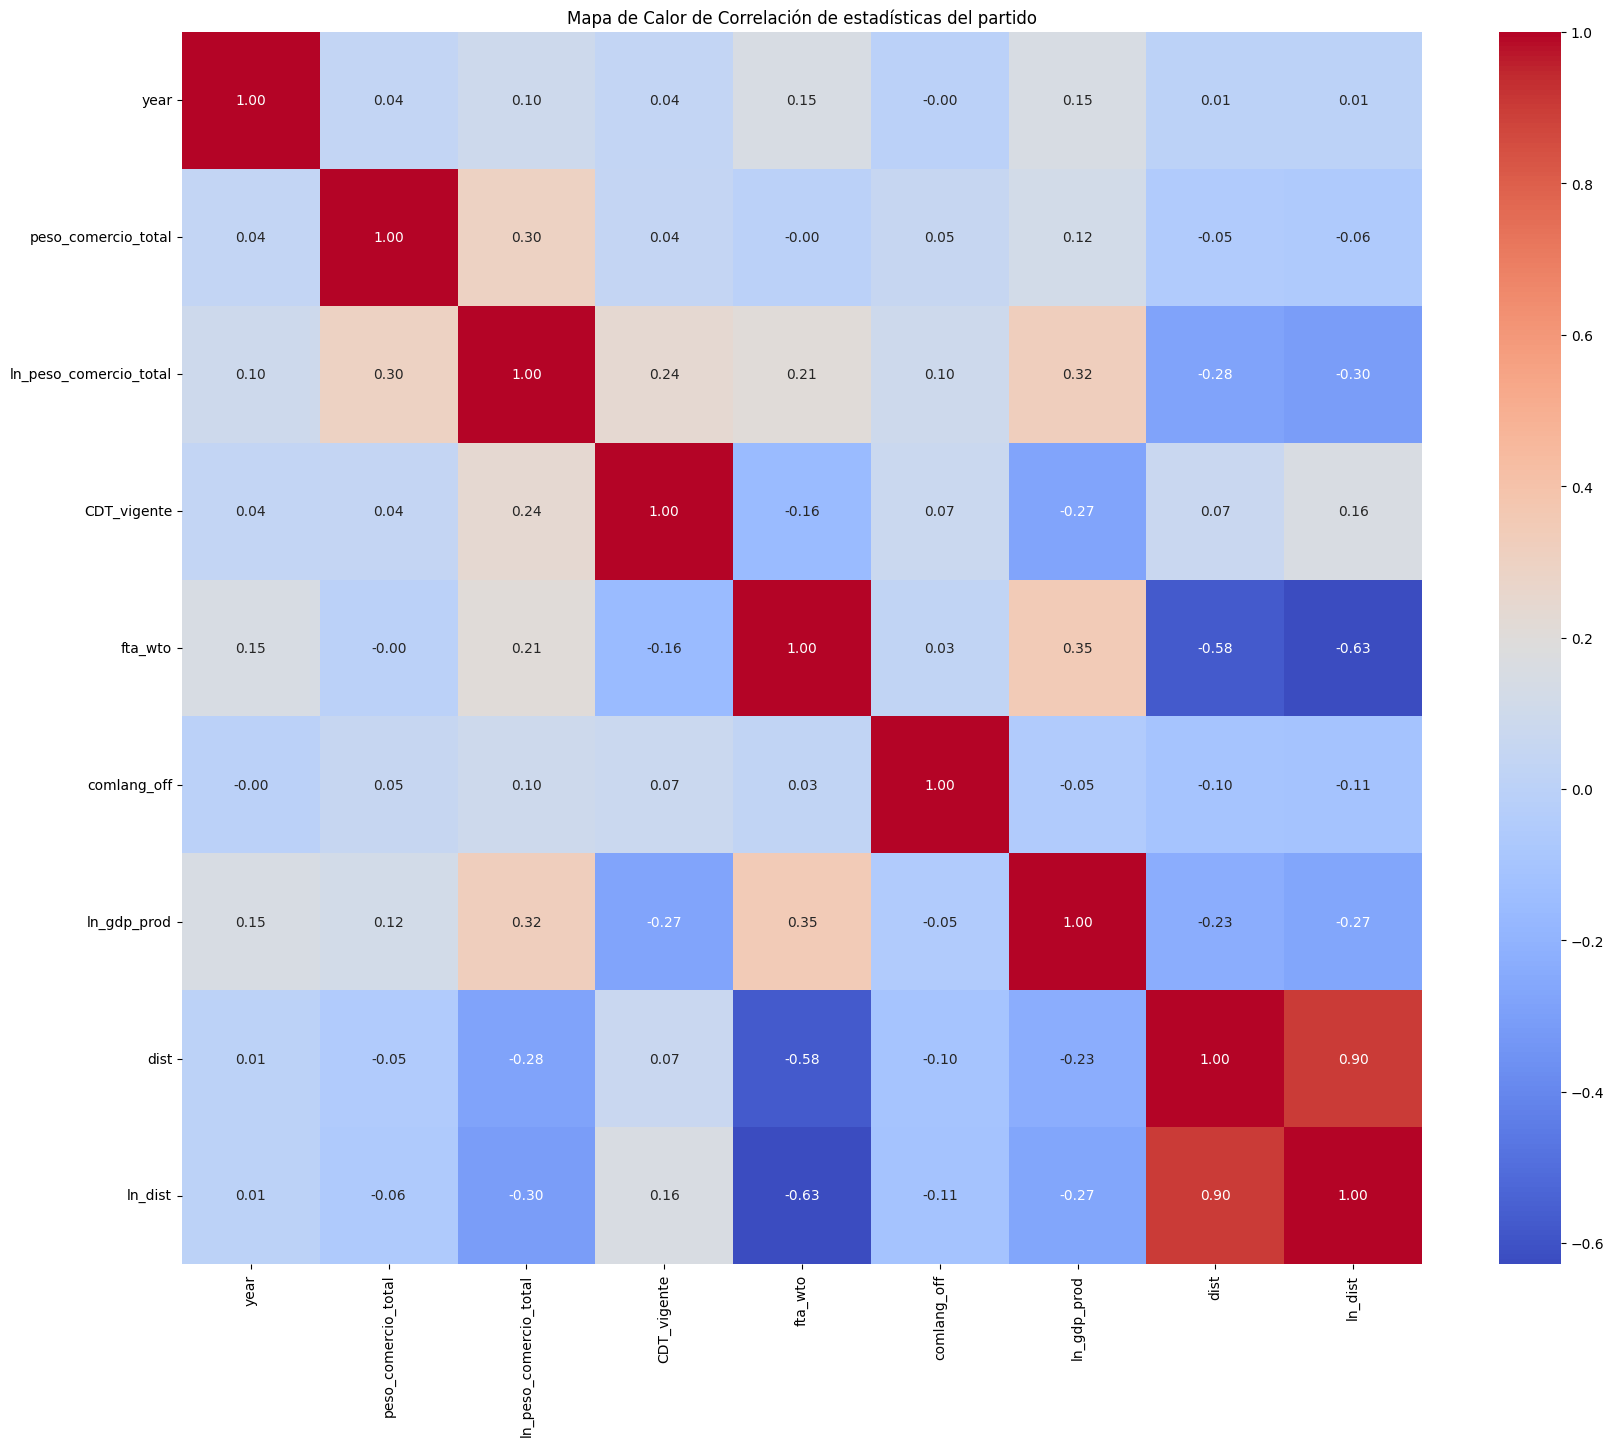

In [134]:
import seaborn as sns
from scipy import stats
baseERGM_VERGM_normalizadas_num=base_para_R.select_dtypes(include=['float64', 'int64'])
matriz_correlacion = baseERGM_VERGM_normalizadas_num.corr()

# Crear el mapa de calor
plt.figure(figsize=(20,16))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Mapa de Calor de Correlación de estadísticas del partido')
plt.show()

In [136]:
print(base_para_R['ln_peso_comercio_total'].describe())

count   63193.00
mean       18.52
std         3.45
min         0.77
25%        16.50
50%        18.99
75%        20.95
max        27.38
Name: ln_peso_comercio_total, dtype: float64


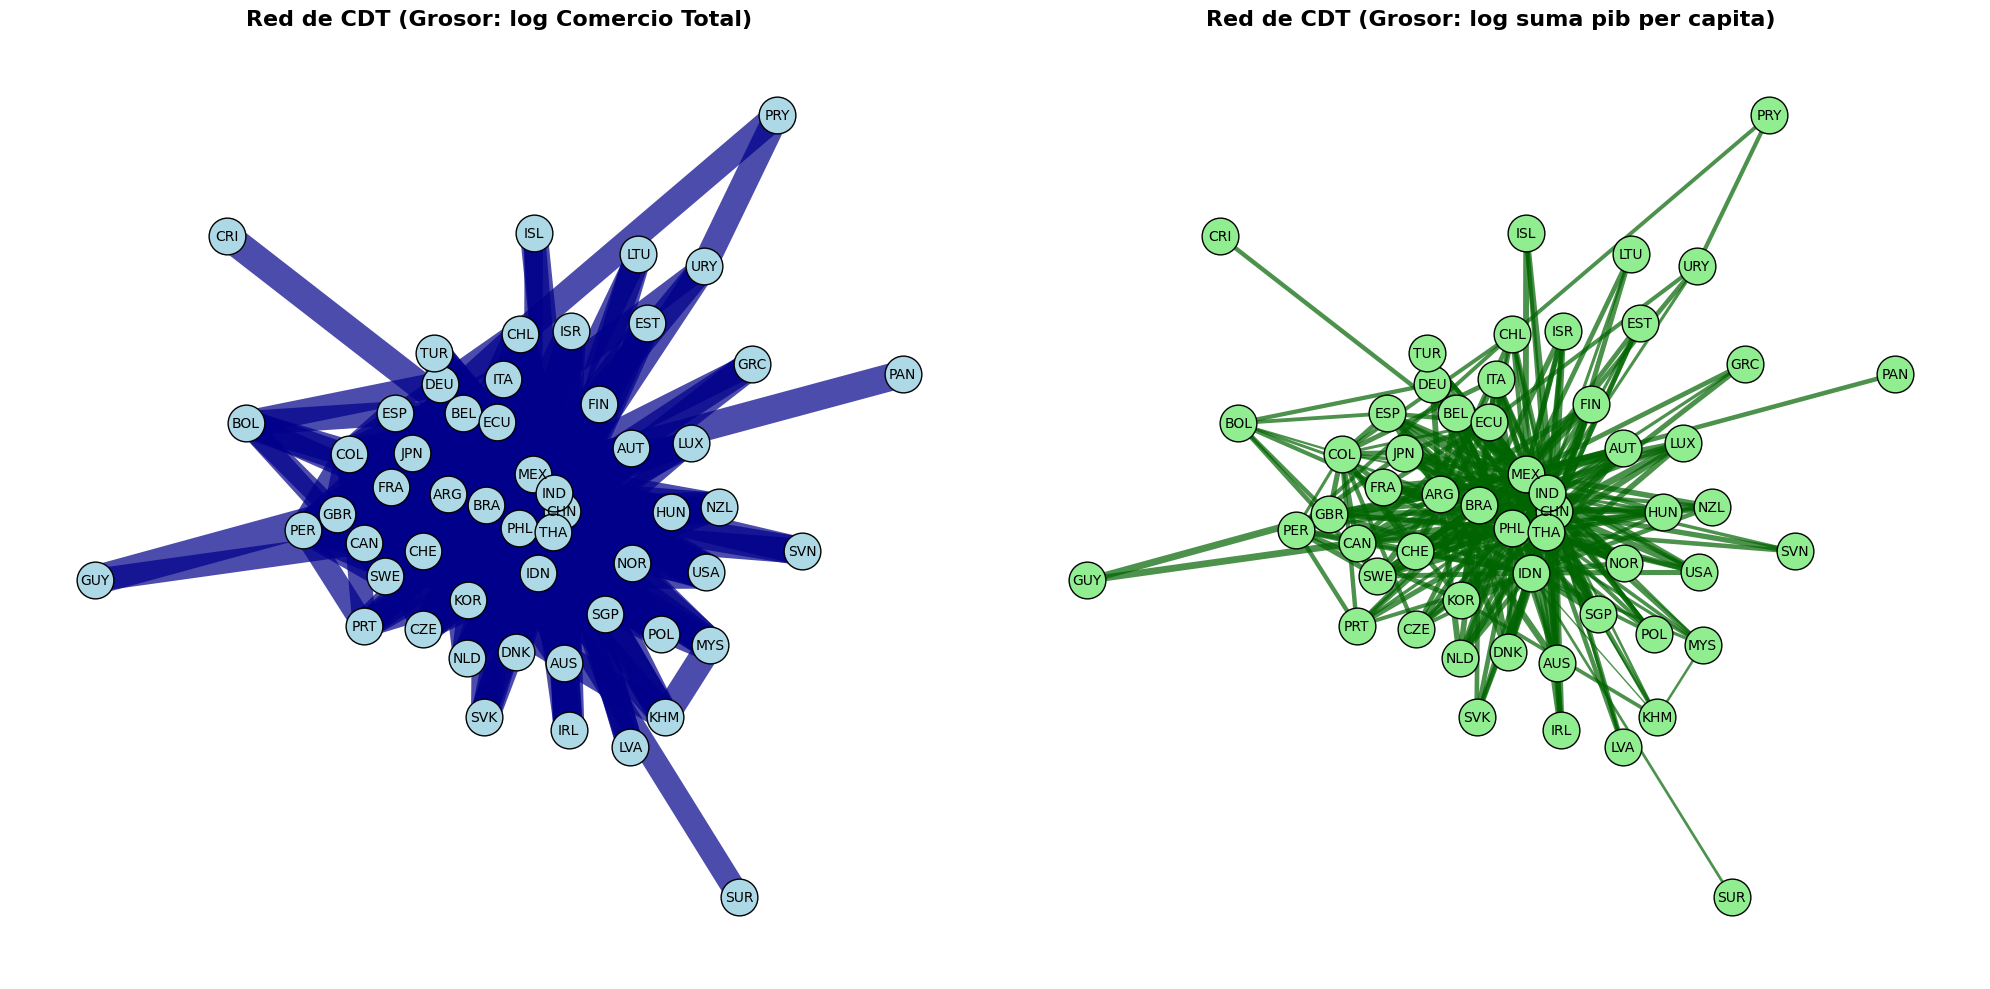

In [139]:
df_red = base_para_R[(base_para_R['year'] == 2024) & (base_para_R['CDT_vigente'] == 1)].copy()
G1 = nx.from_pandas_edgelist(df_red, source='iso3_o', target='iso3_d', edge_attr='ln_peso_comercio_total')
G2 = nx.from_pandas_edgelist(df_red, source='iso3_o', target='iso3_d', edge_attr='ln_gdp_prod')

posiciones = nx.spring_layout(G1, seed=2026, k=0.5)
pesos_g1 = [d['ln_peso_comercio_total'] for (u, v, d) in G1.edges(data=True)]
pesos_g2_crudos = [d['ln_gdp_prod'] for (u, v, d) in G2.edges(data=True)]
min_w = min(pesos_g2_crudos)
max_w = max(pesos_g2_crudos)
pesos_g2 = [(((w - min_w) / (max_w - min_w)) * 4) + 1 for w in pesos_g2_crudos]


fig, axes = plt.subplots(1, 2, figsize=(20, 10))


nx.draw_networkx_nodes(G1, posiciones, ax=axes[0], node_color='lightblue', node_size=700, edgecolors='black')
nx.draw_networkx_edges(G1, posiciones, ax=axes[0], width=pesos_g1, edge_color='darkblue', alpha=0.7)
nx.draw_networkx_labels(G1, posiciones, ax=axes[0], font_size=10, font_family='sans-serif')
axes[0].set_title('Red de CDT (Grosor: log Comercio Total)', fontsize=16, fontweight='bold')
axes[0].axis('off')


nx.draw_networkx_nodes(G2, posiciones, ax=axes[1], node_color='lightgreen', node_size=700, edgecolors='black')
nx.draw_networkx_edges(G2, posiciones, ax=axes[1], width=pesos_g2, edge_color='darkgreen', alpha=0.7)
nx.draw_networkx_labels(G2, posiciones, ax=axes[1], font_size=10, font_family='sans-serif')
axes[1].set_title('Red de CDT (Grosor: log suma pib per capita)', fontsize=16, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()